###Bước 1) Khai báo thư viện và đọc ảnh

Họ và tên: Lê Nguyễn Huy Phát
Mã sinh viên: 6451071057
------------------------------


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


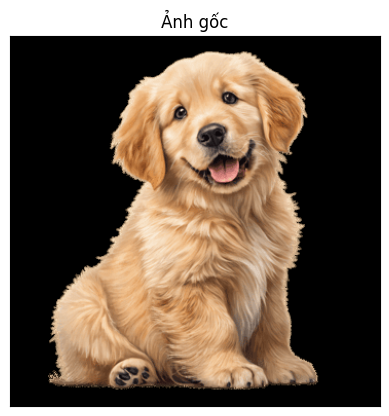

In [1]:
def in_thong_tin():
    print("Họ và tên: Lê Nguyễn Huy Phát")
    print("Mã sinh viên: 6451071057")
    print("-" * 30)

in_thong_tin()

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import os
%matplotlib inline

ten_anh = 'dog.png'     # đổi thành tên ảnh của bạn

if os.path.exists(ten_anh):
    image = Image.open(ten_anh).convert('RGB')
else:
    # Ảnh dự phòng (gradient màu) để chạy thử khi chưa có ảnh
    print("Không thấy file", ten_anh, "- dùng ảnh tạo tự động")
    h, w = 300, 450
    gx, gy = np.meshgrid(np.linspace(0, 255, w), np.linspace(0, 255, h))
    image = Image.fromarray(np.dstack([gx, gy, 255 - gx]).astype(np.uint8))

axes = plt.axes(xticks=[], yticks=[])
axes.imshow(image)
plt.title('Ảnh gốc')
plt.show()

###Bước 2) Chuyển ảnh thành mảng số và lấy kích thước

In [2]:
in_thong_tin()

imarr = np.array(image)
rows = imarr.shape[0]
cols = imarr.shape[1]

print("Kích thước mảng ảnh:", imarr.shape)
print("Chiều cao:", rows, "| Chiều rộng:", cols)
print("Số pixel:", rows * cols)
print("Số màu khác nhau trong ảnh gốc:", len(np.unique(imarr.reshape(-1, 3), axis=0)))

Họ và tên: Lê Nguyễn Huy Phát
Mã sinh viên: 6451071057
------------------------------
Kích thước mảng ảnh: (360, 360, 3)
Chiều cao: 360 | Chiều rộng: 360
Số pixel: 129600
Số màu khác nhau trong ảnh gốc: 226


###Bước 3) Chuẩn hóa và chuyển mảng về dạng 2 chiều

In [3]:
in_thong_tin()

data = imarr / 255.0
data = data.reshape(rows * cols, 3)
print("Kích thước dữ liệu sau reshape:", data.shape)

Họ và tên: Lê Nguyễn Huy Phát
Mã sinh viên: 6451071057
------------------------------
Kích thước dữ liệu sau reshape: (129600, 3)


###Bước 4) Gom cụm k-Means với 32 màu

In [4]:
in_thong_tin()

so_mau = 32
kmeans = KMeans(n_clusters=so_mau, max_iter=300, n_init=3, random_state=42)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

print("Số màu sau khi gom cụm:", so_mau)
print("Bảng 32 màu đại diện (RGB 0-255):")
print((kmeans.cluster_centers_ * 255).astype(int))

Họ và tên: Lê Nguyễn Huy Phát
Mã sinh viên: 6451071057
------------------------------
Số màu sau khi gom cụm: 32
Bảng 32 màu đại diện (RGB 0-255):
[[  0   0   0]
 [190 137  91]
 [233 197 158]
 [122  81  54]
 [220 170 124]
 [243 216 185]
 [157 113  78]
 [192 157 125]
 [ 72  50  39]
 [162 100  53]
 [ 50  37  28]
 [233 189 145]
 [167 141 116]
 [141  99  67]
 [207 138  77]
 [200 151 108]
 [183 121  69]
 [204 172 140]
 [106  88  72]
 [104  66  40]
 [167 125  89]
 [ 32  23  23]
 [216 162 111]
 [226 180 134]
 [134 113  98]
 [186 145 108]
 [241 207 169]
 [210 186 162]
 [ 90  68  55]
 [248 228 203]
 [176 134 100]
 [212 151  95]]


###Bước 5) Khôi phục dạng ảnh và so sánh với ảnh gốc

Họ và tên: Lê Nguyễn Huy Phát
Mã sinh viên: 6451071057
------------------------------


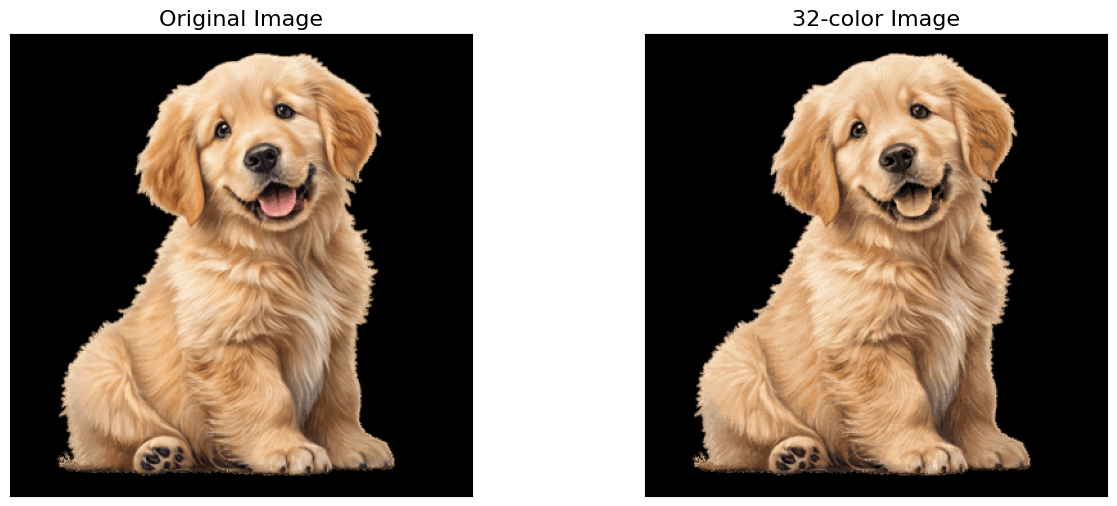

In [5]:
in_thong_tin()

img_recolored = new_colors.reshape(imarr.shape)

fig, ax = plt.subplots(1, 2, figsize=(16, 6),
                       subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(image)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(img_recolored)
ax[1].set_title(f'{so_mau}-color Image', size=16)
plt.show()

###Bước 6) Lưu ảnh kết quả xuống đĩa và so sánh dung lượng

In [6]:
in_thong_tin()

img_out = (img_recolored * 255).astype(np.uint8)
new_img = Image.fromarray(img_out)
new_img.save('compressed_img2.png')

# Lưu thêm bản gốc dạng png để so sánh công bằng
image.save('original_rgb.png')

kt_goc = os.path.getsize('original_rgb.png') / 1024
kt_moi = os.path.getsize('compressed_img2.png') / 1024
print(f"Dung lượng ảnh gốc    : {kt_goc:.1f} KB")
print(f"Dung lượng ảnh 32 màu : {kt_moi:.1f} KB")
print(f"Giảm: {(1 - kt_moi / kt_goc) * 100:.1f}%")

Họ và tên: Lê Nguyễn Huy Phát
Mã sinh viên: 6451071057
------------------------------
Dung lượng ảnh gốc    : 109.0 KB
Dung lượng ảnh 32 màu : 62.2 KB
Giảm: 43.0%


###Bước 7) So sánh các mức số màu khác nhau

Họ và tên: Lê Nguyễn Huy Phát
Mã sinh viên: 6451071057
------------------------------
  4 màu: 7.9 KB


/tmp/ipykernel_715/425070929.py:16: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  pal = Image.fromarray(nhan, mode='P')
/tmp/ipykernel_715/425070929.py:16: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  pal = Image.fromarray(nhan, mode='P')


 16 màu: 19.6 KB


/tmp/ipykernel_715/425070929.py:16: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  pal = Image.fromarray(nhan, mode='P')


 32 màu: 26.0 KB


 64 màu: 31.9 KB


/tmp/ipykernel_715/425070929.py:16: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  pal = Image.fromarray(nhan, mode='P')


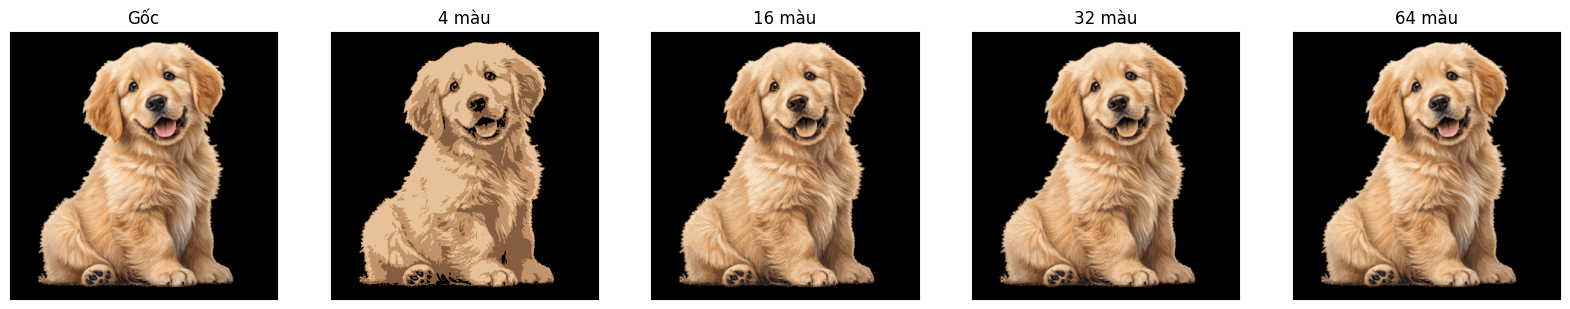

In [7]:
in_thong_tin()

cac_muc = [4, 16, 32, 64]
fig, axes = plt.subplots(1, len(cac_muc) + 1, figsize=(20, 4),
                         subplot_kw=dict(xticks=[], yticks=[]))
axes[0].imshow(image); axes[0].set_title('Gốc')

for ax, k in zip(axes[1:], cac_muc):
    km = KMeans(n_clusters=k, max_iter=300, n_init=1, random_state=42).fit(data)
    anh_k = km.cluster_centers_[km.labels_].reshape(imarr.shape)
    ax.imshow(anh_k)
    ax.set_title(f'{k} màu')

    # Lưu dạng png có bảng màu để thấy rõ dung lượng giảm
    nhan = km.labels_.reshape(rows, cols).astype(np.uint8)
    pal = Image.fromarray(nhan, mode='P')
    pal.putpalette((km.cluster_centers_ * 255).astype(np.uint8).flatten().tolist())
    ten_file = f'compressed_{k}colors.png'
    pal.save(ten_file)
    print(f"{k:>3} màu: {os.path.getsize(ten_file) / 1024:.1f} KB")
plt.show()